# Experimento 013 - YOLO26 completo via TAO + Ultralytics

O cientista fornece uma pasta YOLO local. Este notebook valida o dataset, envia os arquivos ao SeaweedFS, registra o dataset no TAO e submete o treinamento YOLO26 ao adapter Ultralytics. Nenhum `aws`, `curl` ou upload manual é necessário.

In [45]:
import subprocess
import sys
subprocess.check_call([sys.executable, "-m", "pip", "install", "Pillow","boto3", "pyyaml", "requests"])

0

In [46]:
import base64
import io
import json
import os
import time
import shutil
import uuid
import zipfile
from pathlib import Path

import boto3
import requests
import yaml
from IPython.display import display
from PIL import Image
from io import BytesIO

TAO_BASE_URL = os.getenv("TAO_BASE_URL", "http://100.107.81.126:8090").rstrip("/")
ADAPTER_URL = os.getenv("TAO_ULTRALYTICS_URL", "http://100.107.81.126:9200").rstrip("/")
S3_ENDPOINT = os.getenv("TAO_SEAWEEDFS_PUBLIC_ENDPOINT", "http://100.107.81.126:18333")
S3_BUCKET = os.getenv("TAO_SEAWEEDFS_BUCKET", "tao-storage")
S3_ACCESS_KEY = os.getenv("TAO_SEAWEEDFS_ACCESS_KEY", "seaweedfs")
S3_SECRET_KEY = os.getenv("TAO_SEAWEEDFS_SECRET_KEY", "seaweedfs123")
TAO_ORG = os.getenv("TAO_ORG", "getter")
WORKSPACE_ID = os.getenv("TAO_TEST_WORKSPACE_ID", "98c4bec1-88df-423e-8a15-af78881e9742")
LOCAL_DATASET_DIR = Path(os.getenv("YOLO_DATASET_DIR", "/tmp/coco128")).expanduser().resolve()
DATASET_NAME = os.getenv("YOLO_DATASET_NAME", f"coco128-yolo26-{uuid.uuid4().hex[:8]}")
S3_PREFIX = f"data/{DATASET_NAME}"
RUN_EXPERIMENT = os.getenv("RUN_EXPERIMENT_013", "true").lower() == "true"
POLL_SECONDS = int(os.getenv("YOLO_JOB_POLL_SECONDS", "10"))
TIMEOUT_SECONDS = int(os.getenv("YOLO_JOB_TIMEOUT_SECONDS", "3600"))
EPOCHS = int(os.getenv("YOLO_EPOCHS", "20"))
BATCH_SIZE = int(os.getenv("YOLO_BATCH_SIZE", "8"))
IMAGE_SIZE = int(os.getenv("YOLO_IMAGE_SIZE", "640"))
configured = os.getenv("TAO_SECRETS_FILE", "")
candidates = [Path(configured)] if configured else []
candidates += [Path("secrets.json"), Path.cwd() / "secrets.json", Path.cwd().parent / "secrets.json", Path.cwd().parent.parent / "secrets.json"]
secrets_file = next((path for path in candidates if path.exists()), None)
NGC_KEY = json.loads(secrets_file.read_text(encoding="utf-8"))["ngc_api_key"] if secrets_file else os.getenv("NGC_KEY", "")
if not NGC_KEY:
    raise RuntimeError("NGC key not found in secrets.json or TAO_SECRETS_FILE")
http = requests.Session()
print({"tao": TAO_BASE_URL, "adapter": ADAPTER_URL, "s3": S3_ENDPOINT, "dataset": str(LOCAL_DATASET_DIR), "run": RUN_EXPERIMENT})

{'tao': 'http://100.107.81.126:8090', 'adapter': 'http://100.107.81.126:9200', 's3': 'http://100.107.81.126:18333', 'dataset': '/tmp/coco128', 'run': True}


In [47]:
if not (LOCAL_DATASET_DIR / "images/train2017").exists():
    archive = requests.get("https://github.com/ultralytics/assets/releases/download/v0.0.0/coco128.zip", timeout=120)
    archive.raise_for_status()
    with zipfile.ZipFile(io.BytesIO(archive.content)) as zip_file:
        zip_file.extractall(LOCAL_DATASET_DIR.parent)
    downloaded_root = LOCAL_DATASET_DIR.parent / "coco128"
    if downloaded_root != LOCAL_DATASET_DIR:
        if LOCAL_DATASET_DIR.exists():
            shutil.rmtree(LOCAL_DATASET_DIR)
        downloaded_root.rename(LOCAL_DATASET_DIR)
source_yaml = LOCAL_DATASET_DIR / "coco128.yaml"
if not source_yaml.exists():
    source_yaml.write_text(requests.get("https://raw.githubusercontent.com/ultralytics/ultralytics/main/ultralytics/cfg/datasets/coco128.yaml", timeout=60).text, encoding="utf-8")
source_config = yaml.safe_load(source_yaml.read_text(encoding="utf-8")) or {}
data_yaml = LOCAL_DATASET_DIR / "data.yaml"
data_config = {"path": str(LOCAL_DATASET_DIR), "train": "images/train2017", "val": "images/train2017", "nc": len(source_config["names"]), "names": source_config["names"]}
data_yaml.write_text(yaml.safe_dump(data_config, sort_keys=False), encoding="utf-8")
train_dir = LOCAL_DATASET_DIR / data_config["train"]
val_dir = LOCAL_DATASET_DIR / data_config["val"]
if not train_dir.exists() or not val_dir.exists() or not (LOCAL_DATASET_DIR / "labels/train2017").exists():
    raise FileNotFoundError("COCO128 images/labels structure is incomplete")
print({"dataset_validation": "PASS", "dataset": "COCO128", "classes": len(data_config["names"]), "class_names": data_config["names"], "images": len(list(train_dir.glob("*.jpg")))})

{'dataset_validation': 'PASS', 'dataset': 'COCO128', 'classes': 80, 'class_names': {0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: 'carrot', 52: 'hot dog', 53: 'pizza', 54: 'donut', 55: 'cake', 56: 'chair', 57: 'couch', 58: 'potted plant', 59: 'bed', 60: 'dining table', 61: 'toilet', 62: 'tv', 63:

In [48]:
def tao_api(method, path, payload=None, headers=None):
    merged = {"Content-Type": "application/json"}
    if headers:
        merged.update(headers)
    response = http.request(method, TAO_BASE_URL + path, headers=merged, json=payload, timeout=(10, 120))
    response.raise_for_status()
    return response.json() if response.content else None

login = tao_api("POST", "/api/v2/login", {"ngc_key": NGC_KEY, "ngc_org_name": TAO_ORG, "enable_telemetry": False}, {"ngc_key": NGC_KEY})
AUTH = {"Authorization": f"Bearer {login['token']}"}
health = tao_api("GET", "/api/v2/health")
assert "readiness" in health
s3 = boto3.client("s3", endpoint_url=S3_ENDPOINT, aws_access_key_id=S3_ACCESS_KEY, aws_secret_access_key=S3_SECRET_KEY, region_name="us-east-1")
uploaded = 0
for local_file in LOCAL_DATASET_DIR.rglob("*"):
    if local_file.is_file():
        key = f"{S3_PREFIX}/{local_file.relative_to(LOCAL_DATASET_DIR).as_posix()}"
        print(local_file)
        s3.upload_file(str(local_file), S3_BUCKET, key)
        uploaded += 1
DATASET_URI = f"seaweedfs://{S3_BUCKET}/{S3_PREFIX}"
print({"upload": "PASS", "objects": uploaded, "dataset_uri": DATASET_URI})

/tmp/coco128/README.txt
/tmp/coco128/coco128.yaml
/tmp/coco128/LICENSE
/tmp/coco128/data.yaml
/tmp/coco128/images/train2017/000000000581.jpg
/tmp/coco128/images/train2017/000000000643.jpg
/tmp/coco128/images/train2017/000000000109.jpg
/tmp/coco128/images/train2017/000000000536.jpg
/tmp/coco128/images/train2017/000000000326.jpg
/tmp/coco128/images/train2017/000000000510.jpg
/tmp/coco128/images/train2017/000000000382.jpg
/tmp/coco128/images/train2017/000000000315.jpg
/tmp/coco128/images/train2017/000000000349.jpg
/tmp/coco128/images/train2017/000000000263.jpg
/tmp/coco128/images/train2017/000000000144.jpg
/tmp/coco128/images/train2017/000000000143.jpg
/tmp/coco128/images/train2017/000000000113.jpg
/tmp/coco128/images/train2017/000000000368.jpg
/tmp/coco128/images/train2017/000000000127.jpg
/tmp/coco128/images/train2017/000000000073.jpg
/tmp/coco128/images/train2017/000000000370.jpg
/tmp/coco128/images/train2017/000000000438.jpg
/tmp/coco128/images/train2017/000000000036.jpg
/tmp/coco128/

In [49]:
existing = tao_api("GET", f"/api/v2/orgs/{TAO_ORG}/datasets?name={DATASET_NAME}", headers=AUTH)
items = existing.get("datasets", []) if isinstance(existing, dict) else existing
if items:
    tao_dataset = items[0]
else:
    tao_dataset = tao_api("POST", f"/api/v2/orgs/{TAO_ORG}/datasets", {"name": DATASET_NAME, "shared": False, "type": "object_detection", "format": "coco", "workspace": WORKSPACE_ID, "cloud_file_path": S3_PREFIX, "use_for": ["training", "evaluation", "testing"], "skip_validation": True}, AUTH)
TAO_DATASET_ID = tao_dataset.get("id")
print({"tao_dataset_id": TAO_DATASET_ID, "dataset_uri": DATASET_URI})

{'tao_dataset_id': '02a3751f-889e-4729-90b5-f7262291252f', 'dataset_uri': 'seaweedfs://tao-storage/data/coco128-yolo26-3623003c'}


8b608855-6968-4c1a-b590-c14f6d52d6ca train queued
8b608855-6968-4c1a-b590-c14f6d52d6ca train running
8b608855-6968-4c1a-b590-c14f6d52d6ca train running
8b608855-6968-4c1a-b590-c14f6d52d6ca train running
8b608855-6968-4c1a-b590-c14f6d52d6ca train done
a0d14020-16d9-4c4f-b45e-d55e34bc2b31 evaluate running
a0d14020-16d9-4c4f-b45e-d55e34bc2b31 evaluate done
3253ecc1-5116-4c25-b222-7eab677b2659 export running
3253ecc1-5116-4c25-b222-7eab677b2659 export done


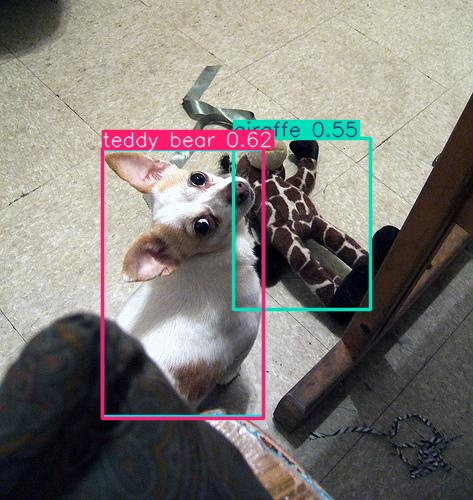

{
  "train": {
    "id": "8b608855-6968-4c1a-b590-c14f6d52d6ca",
    "action": "train",
    "status": "done",
    "model_name": "coco128-yolo26-3623003c",
    "architecture": "yolo26n",
    "dataset_path": null,
    "dataset_uri": "seaweedfs://tao-storage/data/coco128-yolo26-3623003c",
    "tao_workspace_id": "98c4bec1-88df-423e-8a15-af78881e9742",
    "tao_dataset_id": "02a3751f-889e-4729-90b5-f7262291252f",
    "input_size": 640,
    "max_epochs": 20,
    "batch_size": 8,
    "patience": 20,
    "device": "0",
    "train": {
      "epochs": 20,
      "imgsz": 640,
      "batch": 8,
      "patience": 20,
      "device": "0",
      "workers": 1,
      "optimizer": "auto",
      "lr0": 0.01,
      "weight_decay": 0.0005,
      "amp": true,
      "cache": false,
      "seed": 42
    },
    "data_yaml": "/shared-storage/ultralytics-jobs/8b608855-6968-4c1a-b590-c14f6d52d6ca/data.yaml",
    "version": "v1",
    "artifact_path": "/shared-storage/models/yolo26/coco128-yolo26-3623003c/best.pt"

In [50]:
def adapter(method, path, payload=None):
    last_error = None
    for attempt in range(8):
        try:
            response = http.request(method, ADAPTER_URL + path, json=payload, timeout=(10, 120))
            response.raise_for_status()
            return response.json()
        except requests.RequestException as error:
            last_error = error
            if method != "GET" or attempt == 7:
                raise
            time.sleep(min(2 ** attempt, 20))
    raise last_error

def wait_adapter(job_id):
    deadline = time.monotonic() + TIMEOUT_SECONDS
    while time.monotonic() < deadline:
        current = adapter("GET", f"/v1/jobs/{job_id}")
        print(job_id, current.get("action"), current.get("status"))
        if current.get("status") in {"done", "error"}:
            if current["status"] != "done":
                raise RuntimeError(json.dumps(current, indent=2))
            return current
        time.sleep(POLL_SECONDS)
    raise TimeoutError(job_id)

train_payload = {"model_name": DATASET_NAME, "architecture": "yolo26n", "dataset_uri": DATASET_URI, "tao_workspace_id": WORKSPACE_ID, "tao_dataset_id": TAO_DATASET_ID, "input_size": IMAGE_SIZE, "max_epochs": EPOCHS, "batch_size": BATCH_SIZE, "patience": 20, "device": "0", "train": {"epochs": EPOCHS, "imgsz": IMAGE_SIZE, "batch": BATCH_SIZE, "patience": 20, "device": "0", "workers": 1, "optimizer": "auto", "lr0": 0.01, "weight_decay": 0.0005, "amp": True, "cache": False, "seed": 42}}
if not RUN_EXPERIMENT:
    print("dry-run: upload e registro executados; nenhum treino submetido")
else:
    train = adapter("POST", "/v1/jobs/train", train_payload)
    train_result = wait_adapter(train["job_id"])
    evaluate = adapter("POST", f"/v1/jobs/{train['job_id']}/evaluate", {"dataset_uri": DATASET_URI, "input_size": IMAGE_SIZE, "device": "0"})
    evaluate_result = wait_adapter(evaluate["job_id"])
    export = adapter("POST", f"/v1/jobs/{train['job_id']}/export", {"input_size": IMAGE_SIZE, "device": "0"})
    export_result = wait_adapter(export["job_id"])
    inference_image = Path(os.getenv("YOLO_INFERENCE_IMAGE", str(next((LOCAL_DATASET_DIR / "images/train2017").glob("*.jpg")))))
    with inference_image.open("rb") as image_file:
        inference_response = http.post(ADAPTER_URL + "/v1/infer/image", data={"model_name": DATASET_NAME}, files={"file": (inference_image.name, image_file, "image/png")}, timeout=(10, 120))
    inference_response.raise_for_status()
    inference_result = inference_response.json()
    annotated_image = Image.open(BytesIO(base64.b64decode(inference_result["image_base64"])))
    display(annotated_image)
    print(json.dumps({"train": train_result, "evaluate": evaluate_result, "export": export_result, "inference": {"output_path": inference_result["output_path"]}}, indent=2, default=str))